In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

df = pd.read_csv("creditcard.csv")

print("Dataset Shape:", df.shape)
print(df["Class"].value_counts())

Dataset Shape: (284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64


In [6]:
X = df.drop("Class", axis=1)
y = df["Class"]

In [7]:
X_train_all, X_test, y_train_all, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_normal = X_train_all[y_train_all == 0]
X_train, X_val = train_test_split(
    X_normal, test_size=0.1, random_state=42
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)
print("Normal training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

Normal training data: (204705, 30)
Validation data: (22746, 30)
Testing data: (56962, 30)


In [9]:
model = models.Sequential([
    layers.Input(shape=(30,)),
    layers.Dense(14, activation="relu"),
    layers.Dense(7, activation="relu"),
    layers.Dense(4, activation="relu"),
    layers.Dense(7, activation="relu"),
    layers.Dense(14, activation="relu"),
    layers.Dense(30, activation="linear")
])
model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 14)                  │             434 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             105 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 4)                   │              32 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 7)                   │              35 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 14)                  │             112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 30)                  │             450 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,168 (4.56 KB)

 Trainable params: 1,168 (4.56 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.8902 - mae: 0.6424 - val_loss: 0.8081 - val_mae: 0.6196
Epoch 2/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.7869 - mae: 0.6041 - val_loss: 0.7393 - val_mae: 0.5909
Epoch 3/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.7377 - mae: 0.5838 - val_loss: 0.7034 - val_mae: 0.5771
Epoch 4/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.7159 - mae: 0.5738 - val_loss: 0.6866 - val_mae: 0.5698
Epoch 5/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.7005 - mae: 0.5690 - val_loss: 0.6777 - val_mae: 0.5686
Epoch 6/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.6852 - mae: 0.5653 - val_loss: 0.6660 - val_mae: 0.5654
Epoch 7/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6690 - mae: 0.5601 - val_loss: 0.6423 - val_mae: 0.5558
Epoch 8/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6576 - mae: 0.5548 - val_loss: 0.6335 - val_mae: 0.5504
Epoch 9/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - lo

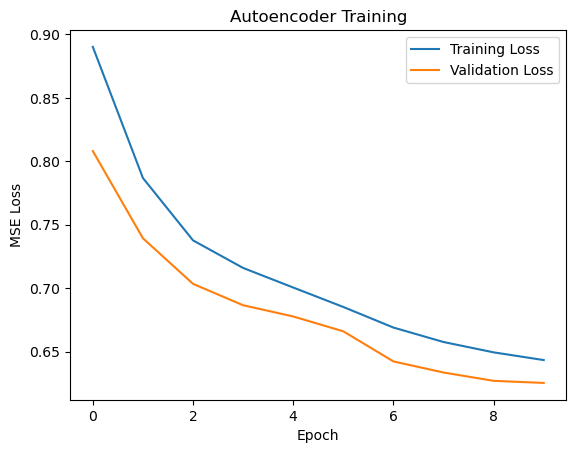

In [10]:
history = model.fit(
    X_train, X_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(X_val, X_val)
)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training")
plt.legend()
plt.show()